# 3. Optimización de hiperparámetros

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** Con el mismo presupuesto de 12 evaluaciones, ¿qué método encuentra mejores hiperparámetros: Grid,
Random, bayesiano (Optuna) o genético (DEAP)?

**Respuesta corta.** Ninguno gana en calidad final (F1 externo de 0.586 a 0.590; Friedman p = 0.74). La
diferencia está en la rapidez: bayesiano, Random y genético llegan al 99 % de su mejor valor en 5 o 6
evaluaciones, y Grid en 10. Successive Halving iguala a Random Search con un cuarto del cómputo en XGBoost, pero
no en Random Forest.
```

Los cuatro métodos optimizan la misma función objetivo: el **F1 macro medio en los 3 pliegues internos**
(kNNDM), ajustando el pipeline completo (preprocesamiento → remuestreo → modelo) dentro de cada pliegue, de modo
que no hay fuga de información. Todos tienen el **mismo presupuesto: 12 evaluaciones** por búsqueda (la rejilla
de Grid se diseñó de 12 puntos), así que la comparación es por unidad de presupuesto. La métrica que se reporta
sale del bucle externo, nunca del óptimo interno.

## 3.1 Espacios de búsqueda

Los rangos salen de la teoría de cada modelo y de los resultados de los entregables anteriores, no de valores
arbitrarios; los que actúan de forma multiplicativa se buscan en **escala logarítmica**.

| Modelo | Hiperparámetros (rango) | Justificación |
|---|---|---|
| KNN | k ∈ [5, 200] (log), pesos uniforme/distancia, métrica L1/L2 | k pequeño = varianza alta; con 6 000 viviendas de entrenamiento interno, 200 vecinos ya son un barrio |
| Naive Bayes | var_smoothing ∈ [10⁻¹¹, 10⁻¹] (log) | suaviza varianzas casi nulas de las variables one-hot |
| Logística L1/L2 | penalización L1 o L2, C ∈ [10⁻³, 10] (log) | el Entregable 1 eligió C = 0.01; L1 permite selección de variables |
| Árbol | profundidad ∈ [3, 30], hojas mínimas ∈ [1, 300] (log), gini/entropía | controla el sobreajuste con dos frenos complementarios |
| Random Forest | árboles ∈ [50, 250] (log), profundidad ∈ [6, 25], variables por corte √p, 30 %, 60 %, hojas mínimas ∈ [1, 50] (log) | más árboles reducen varianza con rendimiento decreciente |
| XGBoost | árboles ∈ [50, 300] (log), learning rate ∈ [0.03, 0.3] (log), profundidad ∈ [3, 8], submuestreo de filas y columnas ∈ [0.5, 1], min_child_weight ∈ [1, 20] (log) | learning rate y número de árboles se compensan: por eso ambos en log |
| SVM (Nyström) | γ ∈ [10⁻³, 1] (log), componentes ∈ [100, 500] (log), C ∈ [10⁻³, 10] (log) | γ fija qué tan local es el kernel; los componentes, la calidad de la aproximación |
| XGBoost geográfico | lo de XGBoost global + fracción de vecinos por ancla ∈ [0.02, 0.3] (log) y α ∈ [0, 1] | α = 1 es el XGBoost global; α = 0, solo modelos locales |

## 3.2 Los cuatro métodos

**Grid Search.** Recorre una rejilla fija de 12 puntos. Es exhaustiva dentro de la rejilla, pero reparte el
presupuesto por igual entre dimensiones importantes y poco importantes.

**Random Search** (Bergstra y Bengio, 2012). 12 configuraciones al azar del espacio (log-uniformes donde
corresponde). Con pocas dimensiones relevantes explora más valores distintos de cada una que una rejilla del
mismo tamaño.

**Optimización bayesiana con Optuna.** El modelo sustituto es el **TPE** (*Tree-structured Parzen
Estimator*; Bergstra et al., 2011), no un proceso gaussiano. TPE separa las evaluaciones hechas en «buenas» y
«malas» (corte en el cuantil γ del puntaje), estima una densidad para cada grupo, $\ell(x)$ y $g(x)$, y propone
la configuración que maximiza $\ell(x)/g(x)$. Maximizar ese cociente equivale a maximizar la **mejora esperada**
(*Expected Improvement*), la función de adquisición. Las 4 primeras evaluaciones son aleatorias (exploración);
después TPE se concentra donde las buenas configuraciones son más densas (explotación). Se usa la versión
multivariada, que modela las interacciones entre hiperparámetros. El pipeline completo se reconstruye y se
ajusta dentro de cada evaluación (Optuna no lo hace por sí solo).

**Algoritmo genético con DEAP.** Cada individuo es un vector en $[0, 1]^d$ que se traduce al espacio de búsqueda
(escala log donde corresponde; los categóricos por intervalos). Operadores:

| Componente | Elección | Por qué |
|---|---|---|
| Selección | torneo de tamaño 3 | presión selectiva moderada, robusta a la escala del F1 |
| Cruce | *blend* (α = 0.5), probabilidad 0.7 | mezcla continua de dos padres; explora entre ellos y un poco más allá |
| Mutación | gaussiana (σ = 0.15 en el genoma), probabilidad 0.3 por individuo y 1/d por gen | perturbaciones locales que mantienen diversidad |
| Elitismo | el mejor individuo pasa intacto a la siguiente generación | el mejor F1 nunca empeora |
| Población | 4 individuos (12 evaluaciones ≈ 3 generaciones) | con un presupuesto tan corto, más individuos serían solo una búsqueda aleatoria |

Se registra la **diversidad genética** (distancia media entre individuos) en cada generación: si cae a cero
muy rápido, la población convergió prematuramente.

## 3.3 Convergencia: desempeño en cualquier momento

Para cada búsqueda se calcula el mejor F1 interno encontrado hasta la evaluación *t*, dividido por el mejor
final. La curva promedio muestra qué tan rápido llega cada método a su mejor solución.

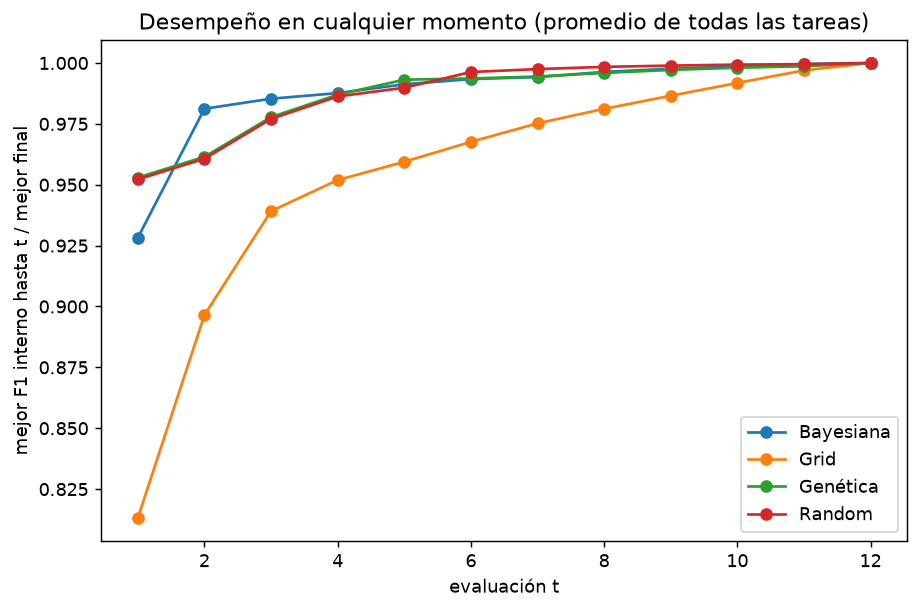

,área bajo la curva (1 = llega al óptimo en la 1.ª evaluación),evaluaciones para alcanzar el 99 %
Bayesiana,0.988,5.0
Grid,0.955,10.0
Genética,0.988,5.0
Random,0.988,6.0


In [1]:
import pandas as pd

from _comun import figura, leer_json

A = leer_json("analisis_clasificacion.json") or {}
figura("anytime_optimizadores.png")
if A.get("anytime"):
    display(pd.DataFrame({m: {"área bajo la curva (1 = llega al óptimo en la 1.ª evaluación)": v["area_bajo_curva"],
                              "evaluaciones para alcanzar el 99 %": v["evals_para_99pct"]}
                          for m, v in A["anytime"].items()}).T.round(3))

**Lectura.** Random, bayesiana y genética llegan al 99 % de su mejor F1 interno en 5 o 6 evaluaciones (área
bajo la curva ≈ 0.988); Grid necesita 10 (área 0.955). La razón es el orden: Grid recorre la rejilla en un
orden fijo y sus primeros puntos suelen ser malos (en la primera evaluación está, en promedio, al 81 % de su
mejor valor, frente al 93–95 % de los otros tres, que empiezan con puntos aleatorios). Con 12 evaluaciones
casi todas las búsquedas terminan en la meseta: un presupuesto mayor mejoraría poco el F1 interno.

## 3.4 Calidad, tiempo y presupuesto

In [2]:
if A.get("optimizadores"):
    op = pd.DataFrame(A["optimizadores"]).T
    op = op[[c for c in op.columns if c.endswith("_mean") or c == "f1_macro_std"]]
    op.columns = [c.replace("_mean", " (media)").replace("_std", " (desv.)") for c in op.columns]
    display(op.round(4))
if A.get("friedman_optimizadores"):
    f = A["friedman_optimizadores"]
    print(f"Friedman entre optimizadores (bloques = modelo × balanceo × pliegue, n = {f['n_bloques']}): "
          f"χ² = {f['chi2']:.2f}, p = {f['p']:.4f}; rangos medios (1 = mejor): {f['rangos']}; CD = {f['cd']:.3f}")

,f1_macro (media),f1_macro (desv.),f1_interno_mejor (media),seg_busqueda (media),seg_por_evaluacion (media),n_evaluaciones (media)
Bayesiana,0.5874,0.0988,0.5978,192.2034,16.0169,12.0000
Genética,0.5885,0.0978,0.5970,214.8613,17.9083,11.9938
Grid,0.5900,0.0984,0.5969,219.1552,18.2629,12.0000
Random,0.5864,0.0994,0.5975,195.2984,16.2749,12.0000


Friedman entre optimizadores (bloques = modelo × balanceo × pliegue, n = 160): χ² = 1.26, p = 0.7388; rangos medios (1 = mejor): {'Bayesiana': 2.412, 'Grid': 2.491, 'Genética': 2.538, 'Random': 2.559}; CD = 0.371


**Lectura.** Los cuatro optimizadores terminan en el mismo sitio. El F1 macro externo medio va de 0.586
(Random) a 0.590 (Grid): diferencias de milésimas, cuando la desviación entre combinaciones es de ≈ 0.10.
Friedman no detecta diferencias (χ² = 1.26, p = 0.74) y los rangos medios (2.41 a 2.56) difieren menos que la
diferencia crítica (0.37). Con 12 evaluaciones y espacios acotados con lo aprendido en los entregables
anteriores, todos encuentran configuraciones en la meseta de buen desempeño; lo que cambia es el costo. La
bayesiana es la más barata (192 s por búsqueda, 16.0 s por evaluación), Random casi igual (195 s), y la
genética y Grid gastan algo más (215 y 219 s), probablemente porque visitan con más frecuencia las zonas caras
del espacio (muchos árboles, profundidad alta). Todos los tiempos se midieron con 8 procesos simultáneos, así
que son comparables entre sí.

El mejor F1 interno (≈ 0.597) sobreestima el F1 externo (≈ 0.588) en todos los métodos: es el sesgo de
optimismo de elegir el máximo entre 12 configuraciones, y la razón de reportar siempre el bucle externo.

## 3.5 Diversidad del algoritmo genético

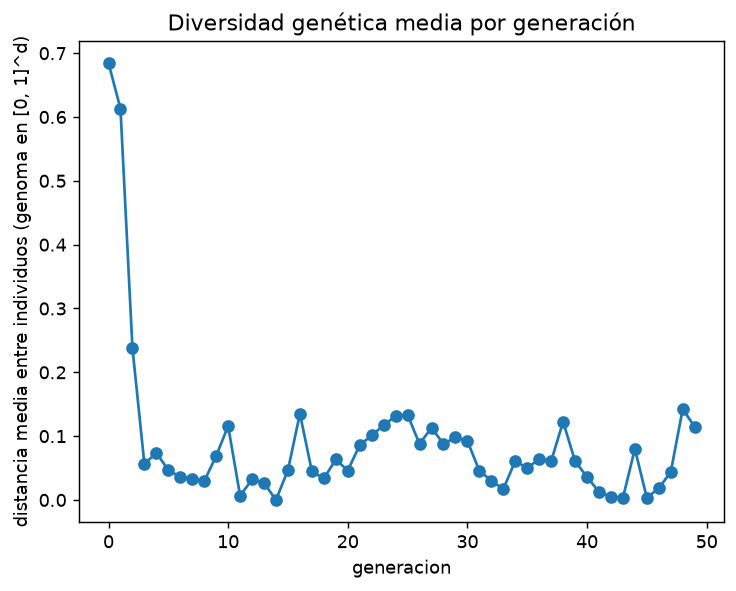

,mean,std,count
0,0.684,0.232,160.0
1,0.613,0.219,160.0
2,0.238,0.240,160.0
3,0.056,0.098,160.0
4,0.074,0.068,150.0
5,0.046,0.039,142.0
6,0.036,0.039,140.0
7,0.033,0.039,129.0
8,0.029,0.051,119.0
9,0.069,0.042,113.0


In [3]:
figura("diversidad_genetica.png")
if A.get("diversidad_genetica"):
    display(pd.DataFrame(A["diversidad_genetica"]).T.round(3))

**Lectura.** La diversidad cae de 0.68 en la población inicial a 0.24 en la generación 2 y a 0.06 en la 3: con
4 individuos, torneo de 3 y elitismo, la población converge muy rápido alrededor del mejor. Desde ahí muchas
crías son copias exactas de configuraciones ya evaluadas; esas no gastan presupuesto (la función objetivo
guarda en memoria las configuraciones ya vistas), por lo que la mitad de las búsquedas necesita más de 10
generaciones para completar sus 12 evaluaciones. Es convergencia prematura, la esperada con un presupuesto tan
corto. Aun así el genético empata con los demás (sección 3.4), porque las 4 configuraciones iniciales
aleatorias ya caen cerca de la meseta y el cruce explora entre ellas. Con más presupuesto convendría una
población mayor (10 o más) o una mutación más fuerte para mantener la diversidad.

## 3.6 Multi-fidelidad

**Successive Halving** (Jamieson y Talwalkar, 2016; `HalvingRandomSearchCV` de scikit-learn) prueba muchas
configuraciones con un presupuesto **parcial** y solo sigue con las más prometedoras:

- **Fidelidad = número de viviendas de entrenamiento.** El costo de todos los modelos crece con n (capítulo 4) y
  el orden de las configuraciones con pocas viviendas se parece al orden con muchas: los hiperparámetros que más
  pesan (profundidad, learning rate, hojas mínimas) no dependen mucho de n en este rango.
- **Factor de reducción η = 3**: en cada ronda queda un tercio de las configuraciones y cada una recibe el triple de
  viviendas. Es el valor por defecto y el que recomiendan Li et al. (2018) para Hyperband.
- **27 configuraciones iniciales** con unas 300 viviendas; luego 9 con unas 900 y 3 con unas 2 700 (y una cuarta
  ronda con 1 configuración cuando el pliegue tiene más de 8 100 viviendas).

Se compara, en los 5 pliegues externos y con los mismos pliegues internos kNNDM, contra Random Search con 12
configuraciones a fidelidad completa, para XGBoost y Random Forest (los dos modelos más caros). El trabajo se mide
en **ajustes equivalentes**: la suma de (viviendas usadas / viviendas del pliegue) sobre todos los ajustes.

In [4]:
MF = leer_json("multifidelidad.json")
if MF:
    mf = pd.DataFrame(MF["resultados"])
    res = mf.groupby("modelo")[["f1_halving", "f1_random", "seg_halving", "seg_random", "configuraciones_halving",
                                "ajustes_equivalentes_halving", "ajustes_random"]].mean()
    res.columns = ["F1 externo Halving", "F1 externo Random", "segundos Halving", "segundos Random",
                   "configuraciones Halving", "ajustes equivalentes Halving", "ajustes Random"]
    display(res.round(3))
    display(mf.round(3))
else:
    print("(multifidelidad pendiente)")

,F1 externo Halving,F1 externo Random,segundos Halving,segundos Random,configuraciones Halving,ajustes equivalentes Halving,ajustes Random
modelo,,,,,,,
Random Forest,0.632,0.651,33.957,77.592,27.0,9.718,36.0
XGBoost,0.650,0.651,44.319,81.198,27.0,9.718,36.0


,modelo,fold,f1_halving,seg_halving,configuraciones_halving,rondas,ajustes_equivalentes_halving,f1_random,seg_random,ajustes_random
0,XGBoost,0,0.672,65.410,27,3,9.178,0.645,69.942,36
1,XGBoost,1,0.764,48.865,27,4,11.999,0.762,91.653,36
2,XGBoost,2,0.574,33.340,27,3,9.124,0.593,75.818,36
3,XGBoost,3,0.598,38.113,27,3,9.153,0.617,72.740,36
4,XGBoost,4,0.644,35.867,27,3,9.138,0.637,95.835,36
5,Random Forest,0,0.658,35.351,27,3,9.178,0.669,70.229,36
6,Random Forest,1,0.745,29.569,27,4,11.999,0.778,90.493,36
7,Random Forest,2,0.499,34.994,27,3,9.124,0.561,79.326,36
8,Random Forest,3,0.598,26.935,27,3,9.153,0.606,71.585,36
9,Random Forest,4,0.660,42.934,27,3,9.138,0.639,76.327,36


**Lectura.** Successive Halving hizo 3 rondas en 4 de los 5 pliegues (27 configuraciones con ≈ 300 viviendas,
9 con ≈ 900 y 3 con ≈ 2 700) y 4 rondas en el pliegue con más de 8 100 viviendas de entrenamiento (una última
con 1 configuración y ≈ 8 100 viviendas). Probó **más del doble de configuraciones** que Random Search (27
frente a 12) con **casi un cuarto del trabajo**: 9.7 ajustes equivalentes a fidelidad completa en promedio,
frente a 36 (12 configuraciones × 3 pliegues internos).

- **XGBoost:** el mismo F1 externo (0.650 frente a 0.651; Halving gana en 3 de 5 pliegues). Aquí la
  multi-fidelidad es una ganancia neta: igual calidad con un cuarto del cómputo.
- **Random Forest:** Halving pierde 0.019 de F1 (0.632 frente a 0.651; gana solo en 1 de 5 pliegues, y en el
  pliegue 2 pierde 0.06). Una explicación probable es que sus frenos se miden en número de viviendas: con 300
  viviendas, `min_samples_leaf` = 30 deja hojas con el 10 % de los datos y la profundidad máxima casi no limita;
  con 8 000, la misma hoja es el 0.4 % y la profundidad sí pesa. El orden de las configuraciones con pocas
  viviendas no se conserva con muchas, y ese es justo el supuesto que necesita la multi-fidelidad.

Los segundos de la tabla no son comparables entre métodos: Halving usó 4 procesos (`n_jobs=4`) y Random Search
uno solo. La medida justa del costo son los ajustes equivalentes. Conclusión: la multi-fidelidad conviene
cuando los hiperparámetros se expresan en escala relativa a n, como la tasa de aprendizaje y la profundidad de
XGBoost; con parámetros absolutos, como las hojas mínimas de Random Forest, hay que reescalarlos o empezar con
una fidelidad más alta.